# 08 - BiLSTM Model

## Objective
Build a Bidirectional LSTM (BiLSTM) model to classify multilingual civic complaints into 12 categories.

## Model Architecture
- Pretrained Word2Vec Embeddings (100 dimensions)
- Bidirectional LSTM (64 units in each direction)
- Dropout (0.3)
- Dense Output Layer (12 classes, Softmax)

## Training Configuration
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy
- Batch Size: 64
- Maximum Epochs: 15
- Early Stopping: Patience 3

## Evaluation
Evaluate using Accuracy, Precision, Recall, F1-score and Confusion Matrix.

In [1]:
# Import libraries required for data loading and model development
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Set random seeds to maintain reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the tokenizer and label encoder saved during preprocessing
with open("../models/preprocessing/tokenizer.pkl", "rb") as file:
    tokenizer = pickle.load(file)

with open("../models/preprocessing/label_encoder.pkl", "rb") as file:
    label_encoder = pickle.load(file)

# Load the maximum sequence length
MAX_LEN = int(np.load("../models/preprocessing/max_len.npy"))

# Load the previously created train, validation and test splits
data = np.load("../models/preprocessing/tokenized_data.npz")

X_train_padded = data["X_train"]
X_val_padded = data["X_val"]
X_test_padded = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

# Load the pretrained Word2Vec embedding matrix
embedding_matrix = np.load(
    "../models/embeddings/word2vec_embedding_matrix.npy"
)

# Define the model configuration
VOCAB_SIZE = len(tokenizer.word_index) + 1
EMBEDDING_DIM = embedding_matrix.shape[1]
NUM_CLASSES = len(label_encoder.classes_)

# Display dataset and model configuration
print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Maximum Sequence Length:", MAX_LEN)
print("Number of Classes:", NUM_CLASSES)

print("\nTraining Shape:", X_train_padded.shape, y_train.shape)
print("Validation Shape:", X_val_padded.shape, y_val.shape)
print("Testing Shape:", X_test_padded.shape, y_test.shape)

Vocabulary Size: 20089
Embedding Dimension: 100
Maximum Sequence Length: 156
Number of Classes: 12

Training Shape: (11563, 156) (11563,)
Validation Shape: (2478, 156) (2478,)
Testing Shape: (2478, 156) (2478,)


In [2]:
# Import the layers required to build the BiLSTM classifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dropout, Dense

# Initialize the BiLSTM model using pretrained Word2Vec embeddings
bilstm_model = Sequential([
    # Load pretrained Word2Vec vectors into the embedding layer
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,
        trainable=True
    ),

    # Process the complaint sequence in both forward and backward directions
    Bidirectional(LSTM(64)),

    # Reduce overfitting during training
    Dropout(0.3),

    # Predict probabilities for the 12 complaint categories
    Dense(NUM_CLASSES, activation="softmax")
])

# Compile the model for multiclass classification
bilstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Build the model using the input sequence length
bilstm_model.build(input_shape=(None, MAX_LEN))

# Display the model architecture and parameter counts
bilstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 156, 100)       │     2,008,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,094,928 (7.99 MB)

 Trainable params: 2,094,928 (7.99 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# Import EarlyStopping to prevent unnecessary training
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve for 3 epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the BiLSTM model using the same training configuration as LSTM
history = bilstm_model.fit(
    X_train_padded,
    y_train,
    validation_data=(X_val_padded, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 19s 92ms/step - accuracy: 0.6768 - loss: 1.0968 - val_accuracy: 0.7809 - val_loss: 0.7365
Epoch 2/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 17s 92ms/step - accuracy: 0.8154 - loss: 0.6452 - val_accuracy: 0.8002 - val_loss: 0.6553
Epoch 3/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 18s 98ms/step - accuracy: 0.8547 - loss: 0.5094 - val_accuracy: 0.8091 - val_loss: 0.6275
Epoch 4/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 18s 102ms/step - accuracy: 0.8769 - loss: 0.4398 - val_accuracy: 0.8148 - val_loss: 0.6349
Epoch 5/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 19s 104ms/step - accuracy: 0.8963 - loss: 0.3718 - val_accuracy: 0.8059 - val_loss: 0.6671
Epoch 6/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 19s 106ms/step - accuracy: 0.9165 - loss: 0.3030 - val_accuracy: 0.8059 - val_loss: 0.6814


In [4]:
# Evaluate the restored best BiLSTM model on training and validation datasets
train_loss, train_accuracy = bilstm_model.evaluate(
    X_train_padded, y_train, verbose=0
)

val_loss, val_accuracy = bilstm_model.evaluate(
    X_val_padded, y_val, verbose=0
)

# Display the final metrics using the restored best weights
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Loss: {train_loss:.4f}")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

Training Accuracy: 0.8781
Training Loss: 0.4217
Validation Accuracy: 0.8091
Validation Loss: 0.6275


In [5]:
# Generate class probabilities for the validation dataset
y_val_prob = bilstm_model.predict(X_val_padded)

# Convert predicted probabilities into class labels
y_val_pred = np.argmax(y_val_prob, axis=1)

# Generate the category-wise precision, recall and F1-score report
print(classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
))

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
                                       precision    recall  f1-score   support

                    Animal Management     0.9752    0.9077    0.9402       130
Civic Infrastructure and Encroachment     0.4286    0.1667    0.2400        36
                Drainage and Sewerage     0.6129    0.5033    0.5527       151
            Electricity and Utilities     0.8421    0.7805    0.8101        41
        Environment and Public Spaces     0.6988    0.5088    0.5888       114
                        Public Safety     0.0000    0.0000    0.0000        30
                    Public Sanitation     0.8814    0.7222    0.7939        72
                  Road Infrastructure     0.7929    0.8890    0.8382       784
                      Street Lighting     0.9078    0.8462    0.8759       221
                Traffic and Transport     0.7249    0.7874    0.7548       174
                     Waste Management     0.8787    0.8787    0.8787       635
           

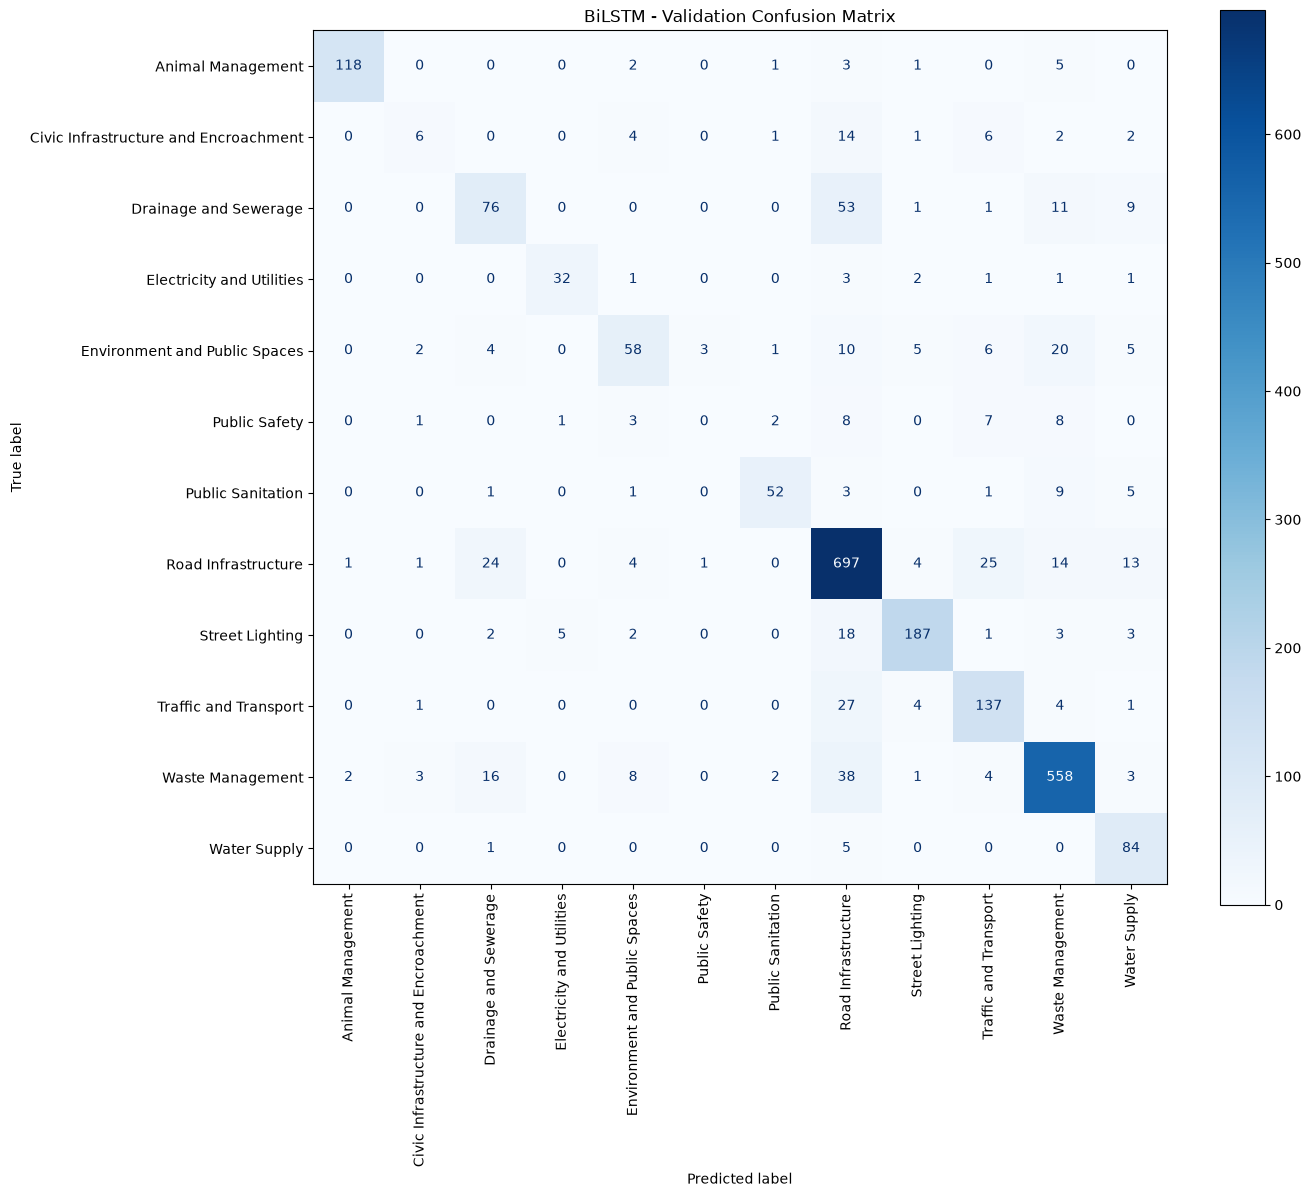

In [9]:
# Import the confusion matrix display utility
from sklearn.metrics import ConfusionMatrixDisplay

# Calculate the confusion matrix using BiLSTM validation predictions
cm = confusion_matrix(y_val, y_val_pred)

# Create a labelled confusion matrix for all 12 categories
plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

# Display the confusion matrix with category labels
disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    ax=plt.gca()
)

plt.title("BiLSTM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
# Create a dedicated directory for the BiLSTM experiment
save_dir = "../models/experiments/bilstm"
os.makedirs(save_dir, exist_ok=True)

# Save the trained BiLSTM model with its best validation weights
bilstm_model.save(
    os.path.join(save_dir, "bilstm_word2vec.keras")
)

# Save training and validation metrics across epochs
pd.DataFrame(history.history).to_csv(
    os.path.join(save_dir, "training_history.csv"),
    index=False
)

# Generate and save the validation classification report
report = classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(save_dir, "validation_classification_report.csv")
)

# Confirm that the experiment files have been saved
print("BiLSTM experiment saved successfully!")
print(os.listdir(save_dir))

BiLSTM experiment saved successfully!
['bilstm_word2vec.keras', 'training_history.csv', 'validation_classification_report.csv']


In [11]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Generate predictions on the untouched test dataset
y_test_prob = bilstm_model.predict(X_test_padded)
y_test_pred = np.argmax(y_test_prob, axis=1)

# Calculate overall test-set performance
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

# Display the final BiLSTM test metrics
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")
print(f"Weighted F1-score: {test_weighted_f1:.4f}")

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Test Accuracy: 0.8184
Macro Precision: 0.7722
Macro Recall: 0.6698
Macro F1-score: 0.6821
Weighted F1-score: 0.8089


In [12]:
# Store the test evaluation metrics in a DataFrame
test_results_df = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted F1-score"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_weighted_f1
    ]
})

# Save the test results in the BiLSTM experiment directory
test_results_df.to_csv(
    os.path.join(save_dir, "test_results.csv"),
    index=False
)

# Confirm successful saving
print("BiLSTM test results saved successfully!")

BiLSTM test results saved successfully!
